In [1]:
!pip -q install kagglehub opencv-python-headless scikit-learn seaborn tqdm

## 2. Download the dataset automatically

In [2]:
import os, pathlib, subprocess, sys, glob, zipfile, shutil
import kagglehub

DATASET_SLUG = "shahliza27/ur-fall-detection-dataset"

try:
    DATASET_DIR = kagglehub.dataset_download(DATASET_SLUG)
    print("Dataset downloaded to:", DATASET_DIR)
except Exception as e:
    print("KaggleHub download failed:", repr(e))
    print("\\nTrying Kaggle API using Colab Secrets...")
    try:
        from google.colab import userdata
        username = userdata.get("KAGGLE_USERNAME")
        key = userdata.get("KAGGLE_KEY")
        if not username or not key:
            raise RuntimeError("KAGGLE_USERNAME or KAGGLE_KEY secret is missing.")
        os.makedirs("/root/.kaggle", exist_ok=True)
        import json
        with open("/root/.kaggle/kaggle.json", "w") as f:
            json.dump({"username": username, "key": key}, f)
        os.chmod("/root/.kaggle/kaggle.json", 0o600)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
        os.makedirs("/content/urfd_dataset", exist_ok=True)
        subprocess.run([
            "kaggle", "datasets", "download", "-d", DATASET_SLUG,
            "-p", "/content/urfd_dataset", "--unzip"
        ], check=True)
        DATASET_DIR = "/content/urfd_dataset"
    except Exception as auth_error:
        raise RuntimeError(
            "Automatic download could not complete. In Colab, open the key icon (Secrets), "
            "add KAGGLE_USERNAME and KAGGLE_KEY from your Kaggle account, enable notebook access, "
            "then rerun this cell. Original error: " + str(auth_error)
        )

print("Top-level contents:")
for item in os.listdir(DATASET_DIR)[:30]:
    print(" •", item)

Using Colab cache for faster access to the 'ur-fall-detection-dataset' dataset.
Dataset downloaded to: /kaggle/input/ur-fall-detection-dataset
Top-level contents:
 • UR_fall_detection_dataset_cam0_rgb


## 3. Find image frames and inspect dataset structure

URFD stores each sequence as an ordered set of image frames (often PNG files), not necessarily as playable image-frame files. This cell also extracts any ZIP archives included in the Kaggle download.

In [3]:
import os, cv2, numpy as np, pandas as pd, re, zipfile
from pathlib import Path
from collections import Counter
from PIL import Image

# Extract ZIP archives if the Kaggle mirror contains the original per-sequence archives.
EXTRACT_ROOT = Path("/content/urfd_extracted")
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
zip_files = list(Path(DATASET_DIR).rglob("*.zip"))
print("ZIP archives found:", len(zip_files))
for zpath in zip_files:
    target = EXTRACT_ROOT / zpath.stem
    if not target.exists() or not any(target.iterdir()):
        target.mkdir(parents=True, exist_ok=True)
        try:
            with zipfile.ZipFile(zpath, "r") as zf:
                zf.extractall(target)
        except zipfile.BadZipFile:
            print("Skipping invalid ZIP:", zpath)

# Search both the Kaggle download and extracted archives.
SEARCH_ROOTS = [Path(DATASET_DIR), EXTRACT_ROOT]
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp"}
image_paths = []
for root in SEARCH_ROOTS:
    if root.exists():
        image_paths.extend([p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS])

# Remove duplicates while preserving order.
image_paths = list(dict.fromkeys(image_paths))
print("Image frames found:", len(image_paths))
print("Example frame paths:")
for pth in image_paths[:25]:
    print(pth)

ZIP archives found: 0
Image frames found: 11936
Example frame paths:
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-057.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-034.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-178.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-126.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-002.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-103.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-153.png
/kaggle/input/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb/adl-07-cam0-rgb/adl-07-cam0-rgb-174.png
/kaggle/inp

### Identify sequence folders and class labels

The model needs a sequence of frames from one recording, not unrelated images mixed together. The code groups frames by their containing sequence folder. It can also group images stored directly in a class folder when filenames contain a sequence name followed by a frame number.

**Label convention:** `Fall = 1`; `ADL / Non-Fall = 0`. The code checks folder and filename names. Review the detected class counts before proceeding.

In [4]:
def infer_label(path):
    # Search path components and filename for class/sequence naming conventions.
    s = str(path).lower().replace("_", "-").replace(" ", "-")
    parts = [x.lower().replace("_", "-") for x in Path(path).parts]
    # ADL / non-fall terms must be checked before the general word "fall".
    if any(("adl" in x) or ("nonfall" in x) or ("non-fall" in x) or ("non-falls" in x) for x in parts):
        return 0
    if any(re.search(r"(^|[-_/])fall(s)?([\-_/0-9]|$)", x) for x in parts):
        return 1
    # Common URFD sequence names: fall-01... and adl-01...
    name = Path(path).name.lower()
    if re.match(r"adl[-_]", name):
        return 0
    if re.match(r"fall[-_]", name):
        return 1
    return None

def sequence_key(img_path):
    # Normal layout: one directory per sequence, with many frame images inside.
    parent = img_path.parent
    parent_images = [p for p in parent.iterdir()
                     if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    if len(parent_images) >= 2:
        return str(parent)

    # Alternative layout: frames from several sequences stored in one class folder.
    # Strip a trailing frame number, e.g. fall-01-cam0-rgb-000123.png.
    stem = img_path.stem
    stem = re.sub(r"[-_ ]?\d{3,}$", "", stem)
    return str(parent / stem)

groups = {}
for img_path in image_paths:
    key = sequence_key(img_path)
    groups.setdefault(key, []).append(img_path)

records = []
for key, frames in groups.items():
    frames = sorted(frames, key=lambda p: p.name.lower())
    label = infer_label(key)
    if label is None:
        # Fall back to any filename in the sequence.
        label = infer_label(frames[0])
    records.append({
        "sequence_id": Path(key).name,
        "sequence_path": key,
        "frames": [str(x) for x in frames],
        "num_frames": len(frames),
        "label": label,
        "class": {0: "Non-Fall (ADL)", 1: "Fall"}.get(label, "Unknown")
    })

df_all = pd.DataFrame(records)
print("Detected image sequences:", len(df_all))
print("Detected labels:")
display(df_all["class"].value_counts(dropna=False).to_frame("Sequences"))
print("\\nExample sequences:")
display(df_all[["sequence_id", "num_frames", "class"]].head(15))

unknown = df_all[df_all.label.isna()]
if len(unknown):
    print("\\nSequences whose class could not be inferred. Inspect these paths:")
    display(unknown[["sequence_path", "num_frames"]].head(30))
    print("If needed, update infer_label() to match the folder names in this Kaggle copy.")

df = df_all.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)
if df.empty or df.label.nunique() < 2:
    raise ValueError("Could not detect both Fall and ADL sequences. Inspect the paths above and adjust infer_label().")
print("\\nUsable labelled sequences:", len(df))

Detected image sequences: 70
Detected labels:


,Sequences
class,
Non-Fall (ADL),40
Fall,30


\nExample sequences:


,sequence_id,num_frames,class
0,adl-07-cam0-rgb,180,Non-Fall (ADL)
1,adl-32-cam0-rgb,200,Non-Fall (ADL)
2,adl-28-cam0-rgb,85,Non-Fall (ADL)
3,fall-29-cam0-rgb,99,Fall
4,fall-24-cam0-rgb,60,Fall
5,fall-07-cam0-rgb,156,Fall
6,fall-16-cam0-rgb,55,Fall
7,adl-02-cam0-rgb,180,Non-Fall (ADL)
8,adl-35-cam0-rgb,280,Non-Fall (ADL)
9,fall-11-cam0-rgb,130,Fall


\nUsable labelled sequences: 70


## 4. Verify image frames and visually explore samples

Corrupted images are removed from each sequence. A sequence is retained only if it has at least 16 readable frames, so the model can sample a complete fixed-length clip.

In [5]:
def valid_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

clean_records = []
for _, row in df.iterrows():
    good_frames = [p for p in row.frames if valid_image(p)]
    if len(good_frames) >= 16:
        clean_records.append({
            **row.to_dict(),
            "frames": good_frames,
            "num_frames": len(good_frames)
        })

df = pd.DataFrame(clean_records).reset_index(drop=True)
print("Valid sequences after corrupted-frame removal:", len(df))
print("Class distribution:")
display(df["class"].value_counts().to_frame("Sequences"))
display(df[["sequence_id", "num_frames", "class"]].head(10))
if len(df) < 10 or df.label.nunique() < 2:
    raise ValueError("Too few valid sequences or one class is missing. Check the dataset structure and labels.")

Valid sequences after corrupted-frame removal: 70
Class distribution:


,Sequences
class,
Non-Fall (ADL),40
Fall,30


,sequence_id,num_frames,class
0,adl-07-cam0-rgb,180,Non-Fall (ADL)
1,adl-32-cam0-rgb,200,Non-Fall (ADL)
2,adl-28-cam0-rgb,85,Non-Fall (ADL)
3,fall-29-cam0-rgb,99,Fall
4,fall-24-cam0-rgb,60,Fall
5,fall-07-cam0-rgb,156,Fall
6,fall-16-cam0-rgb,55,Fall
7,adl-02-cam0-rgb,180,Non-Fall (ADL)
8,adl-35-cam0-rgb,280,Non-Fall (ADL)
9,fall-11-cam0-rgb,130,Fall


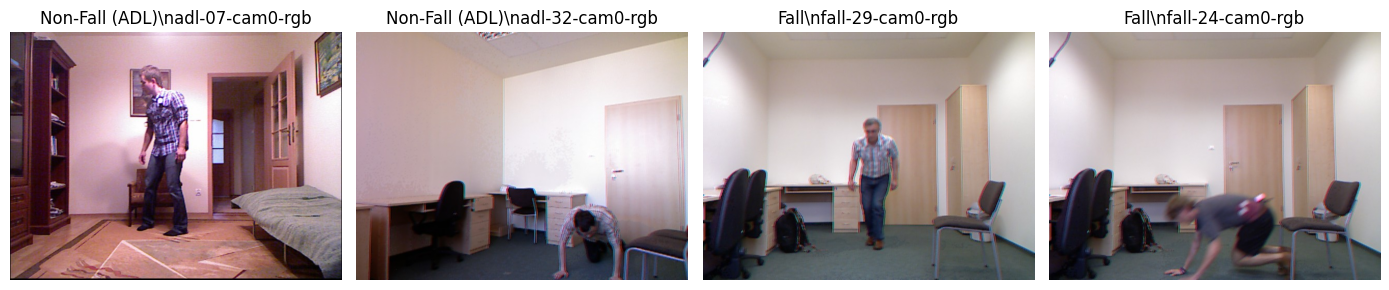

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

def read_preview_frame(frame_paths, fraction=0.5):
    if not frame_paths:
        return None
    idx = min(len(frame_paths)-1, int((len(frame_paths)-1)*fraction))
    try:
        with Image.open(frame_paths[idx]) as im:
            return np.array(im.convert("RGB"))
    except Exception:
        return None

sample_rows = pd.concat([df[df.label == 0].head(2), df[df.label == 1].head(2)])
fig, axes = plt.subplots(1, len(sample_rows), figsize=(14,4))
if len(sample_rows) == 1:
    axes = [axes]
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    frame = read_preview_frame(row.frames)
    if frame is not None:
        ax.imshow(frame)
    ax.set_title(f'{row["class"]}\\n{row["sequence_id"]}')
    ax.axis("off")
plt.tight_layout()
plt.show()

**Visual interpretation:** ADL clips show ordinary daily movements (for example walking, sitting, or standing), while fall clips contain a loss of balance/descent to the floor. The actual appearance depends on camera position, occlusion, and lighting.

## 5. Preprocess image sequences into fixed-size 3D tensors

Each sequence is a list of chronologically ordered image files. We sample 16 frames, resize each frame to 112 × 112, convert to RGB, normalize pixels to [0, 1], and stack the frames into a tensor with shape **channels × frames × height × width** for PyTorch Conv3D.

In [7]:
import random, math, torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split

SEQUENCE_LENGTH = 16
IMAGE_SIZE = 112
BATCH_SIZE = 2  # Increase to 4 if GPU memory permits.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

def natural_key(path):
    # Natural sorting keeps frame_2 before frame_10.
    return [int(t) if t.isdigit() else t.lower()
            for t in re.split(r"(\\d+)", Path(path).name)]

def load_image_sequence(frame_paths, sequence_length=SEQUENCE_LENGTH,
                        image_size=IMAGE_SIZE, training=False):
    frame_paths = sorted(frame_paths, key=natural_key)
    total = len(frame_paths)
    if total < sequence_length:
        raise ValueError(f"Sequence has only {total} frames; need {sequence_length}.")

    # Even temporal sampling; training uses a random temporal window (jitter).
    if training and total > sequence_length:
        span = random.randint(sequence_length, total)
        start = random.randint(0, total - span)
        indices = np.linspace(start, start + span - 1, sequence_length).astype(int)
    else:
        indices = np.linspace(0, total - 1, sequence_length).astype(int)

    frames = []
    for idx in indices:
        with Image.open(frame_paths[int(idx)]) as im:
            arr = np.array(im.convert("RGB").resize((image_size, image_size), Image.Resampling.BILINEAR))
        frames.append(arr)

    clip = np.stack(frames).astype(np.float32) / 255.0  # T,H,W,C in [0,1]

    # Apply the same spatial augmentation to every frame in a clip.
    if training:
        if random.random() < 0.5:
            clip = clip[:, :, ::-1, :].copy()
        if random.random() < 0.5:
            h, w = clip.shape[1:3]
            margin = max(1, int(0.08 * image_size))
            top = random.randint(0, margin)
            left = random.randint(0, margin)
            crop = clip[:, top:h-margin+top, left:w-margin+left, :]
            clip = np.stack([
                cv2.resize(frame, (image_size, image_size)) for frame in crop
            ]).astype(np.float32)

    # Conv3D expects C,T,H,W for an individual sample.
    return torch.from_numpy(np.transpose(clip, (3, 0, 1, 2)).copy())

Device: cuda


## 6. Train/validation/test split (70% / 15% / 15%)

In [8]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")
print("\\nClass distribution:")
display(pd.DataFrame({
    "Train": train_df.label.value_counts(),
    "Validation": val_df.label.value_counts(),
    "Test": test_df.label.value_counts()
}).fillna(0).astype(int))

Train: 49 (70.0%)
Validation: 10 (14.3%)
Test: 11 (15.7%)
\nClass distribution:


,Train,Validation,Test
label,,,
0,28,6,6
1,21,4,5


In [9]:
class FallVideoDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        clip = load_image_sequence(row.frames, training=self.training)
        return clip, torch.tensor(int(row.label), dtype=torch.long)

train_ds = FallVideoDataset(train_df, training=True)
val_ds = FallVideoDataset(val_df, training=False)
test_ds = FallVideoDataset(test_df, training=False)

# WeightedRandomSampler oversamples the minority class during training.
class_counts = train_df.label.value_counts().to_dict()
sample_weights = [1.0 / class_counts[int(y)] for y in train_df.label]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

x, y = next(iter(train_loader))
print("Batch tensor shape:", x.shape, "(batch, channels, frames, height, width)")
print("Pixel range:", x.min().item(), "to", x.max().item())

Batch tensor shape: torch.Size([2, 3, 16, 112, 112]) (batch, channels, frames, height, width)
Pixel range: 0.0 to 0.9960784316062927


## 7. Build the baseline 3D CNN

In [10]:
import torch.nn as nn

class Fall3DCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16), nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1,2,2)),
            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(2,2,2)),
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool3d((1,1,1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = Fall3DCNN().to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Fall3DCNN(
  (features): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (5): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (8): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (9): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): AdaptiveAvgPool3d(output_size=(1, 1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
  

## 8. Train the model

In [11]:
from sklearn.metrics import accuracy_score
import copy, time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
EPOCHS = 10  # increase to 15-25 for a longer experiment if time/GPU allows

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, all_y, all_pred = 0.0, [], []
    for clips, labels in loader:
        clips, labels = clips.to(DEVICE), labels.to(DEVICE)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(clips)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * labels.size(0)
        all_y.extend(labels.cpu().numpy())
        all_pred.extend(logits.argmax(1).detach().cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(all_y, all_pred)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    start = time.time()
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | "
          f"train loss {train_loss:.4f}, acc {train_acc:.3f} | "
          f"val loss {val_loss:.4f}, acc {val_acc:.3f} | "
          f"{time.time()-start:.1f}s")

model.load_state_dict(best_state)

Epoch 01/10 | train loss 0.6499, acc 0.592 | val loss 0.6091, acc 0.900 | 14.4s
Epoch 02/10 | train loss 0.7016, acc 0.551 | val loss 0.5102, acc 0.900 | 16.6s
Epoch 03/10 | train loss 0.6049, acc 0.673 | val loss 0.4185, acc 0.900 | 16.5s
Epoch 04/10 | train loss 0.6146, acc 0.653 | val loss 0.4664, acc 0.800 | 13.0s
Epoch 05/10 | train loss 0.5115, acc 0.816 | val loss 0.4364, acc 0.800 | 13.4s
Epoch 06/10 | train loss 0.5293, acc 0.714 | val loss 0.5022, acc 0.800 | 12.7s
Epoch 07/10 | train loss 0.4682, acc 0.735 | val loss 0.3114, acc 0.900 | 13.5s
Epoch 08/10 | train loss 0.5516, acc 0.694 | val loss 0.3247, acc 0.900 | 13.2s
Epoch 09/10 | train loss 0.5898, acc 0.592 | val loss 0.3034, acc 0.900 | 12.6s
Epoch 10/10 | train loss 0.5316, acc 0.857 | val loss 0.2582, acc 0.900 | 12.5s


<All keys matched successfully>

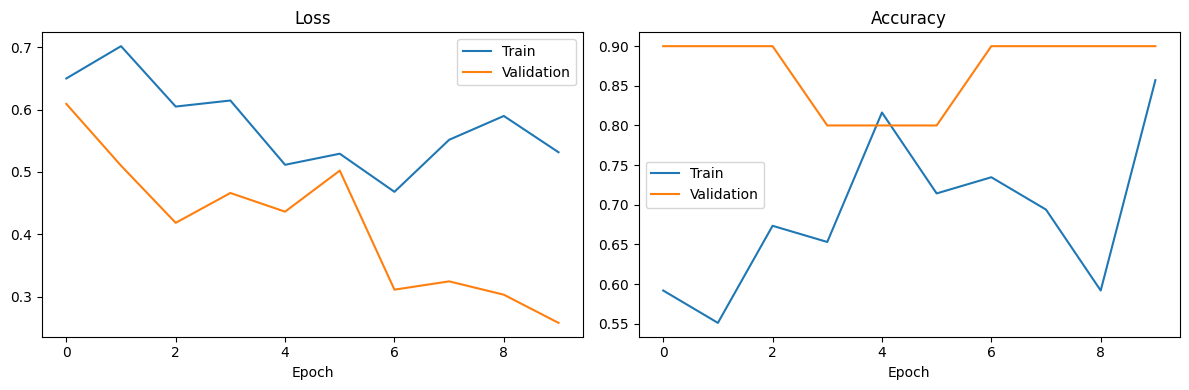

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Test evaluation: Accuracy, Precision, Recall, F1-score, AUROC

In [13]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

model.eval()
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for clips, labels in test_loader:
        clips = clips.to(DEVICE)
        logits = model(clips)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        y_true.extend(labels.numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
auroc = roc_auc_score(y_true, y_prob) if len(set(y_true)) == 2 else float("nan")

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUROC"],
    "Score": [accuracy, precision, recall, f1, auroc]
})
display(metrics.round(4))
print(classification_report(y_true, y_pred, target_names=["Non-Fall (ADL)", "Fall"], zero_division=0))

,Metric,Score
0,Accuracy,0.8182
1,Precision,0.7143
2,Recall,1.0000
3,F1-score,0.8333
4,AUROC,1.0000


                precision    recall  f1-score   support

Non-Fall (ADL)       1.00      0.67      0.80         6
          Fall       0.71      1.00      0.83         5

      accuracy                           0.82        11
     macro avg       0.86      0.83      0.82        11
  weighted avg       0.87      0.82      0.82        11



## 10. Confusion matrix and ROC curve

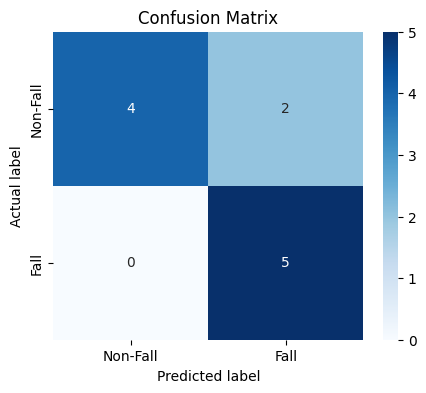

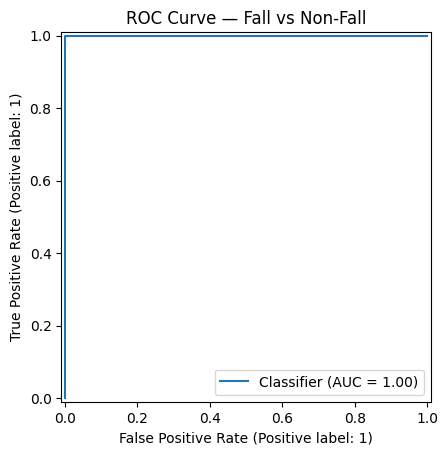

In [14]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1])
import seaborn as sns
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Fall", "Fall"], yticklabels=["Non-Fall", "Fall"])
plt.xlabel("Predicted label"); plt.ylabel("Actual label")
plt.title("Confusion Matrix"); plt.show()

if len(set(y_true)) == 2:
    RocCurveDisplay.from_predictions(y_true, y_prob)
    plt.title("ROC Curve — Fall vs Non-Fall")
    plt.show()
else:
    print("ROC curve unavailable because the test set contains only one class.")

## 11. Error analysis and discussion

Use the confusion matrix to identify:
- **False Positive:** an ADL video predicted as a fall (may happen during sitting quickly, bending, or lying down).
- **False Negative:** a fall video predicted as ADL (important in healthcare because a fall may go undetected).

Relate incorrectly classified examples to the source lab's suggested factors:
1. **Camera view:** a side/front view can change the apparent body movement.
2. **Occlusion:** furniture or another object may hide part of the person's body.
3. **Motion blur:** rapid movement can make frames unclear.

The following cell lists test clips that were misclassified so they can be reviewed visually.

In [15]:
errors = []
for i, (_, row) in enumerate(test_df.reset_index(drop=True).iterrows()):
    if y_true[i] != y_pred[i]:
        errors.append({
            "sequence_id": row.sequence_id,
            "sequence_path": row.sequence_path,
            "actual": "Fall" if y_true[i] == 1 else "Non-Fall",
            "predicted": "Fall" if y_pred[i] == 1 else "Non-Fall",
            "fall_probability": float(y_prob[i])
        })
error_df = pd.DataFrame(errors)
print("Misclassified test sequences:", len(error_df))
display(error_df)

Misclassified test sequences: 2


,sequence_id,sequence_path,actual,predicted,fall_probability
0,adl-34-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,Non-Fall,Fall,0.670361
1,adl-25-cam0-rgb,/kaggle/input/ur-fall-detection-dataset/UR_fal...,Non-Fall,Fall,0.550704


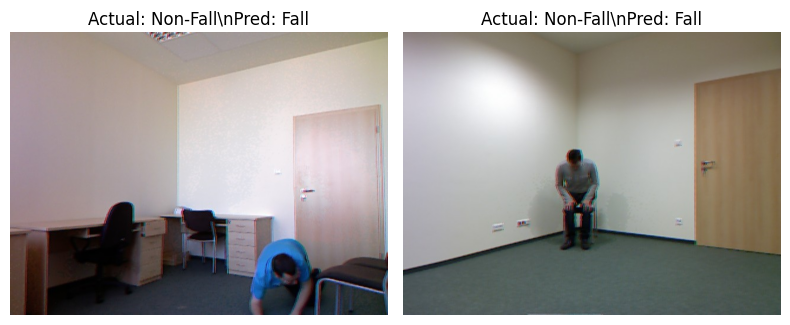

In [16]:
if len(error_df):
    n = min(4, len(error_df))
    fig, axes = plt.subplots(1, n, figsize=(4*n,4))
    if n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, error_df.head(n).iterrows()):
        matching = df[df.sequence_id == row.sequence_id].iloc[0]
        frame = read_preview_frame(matching.frames)
        if frame is not None:
            ax.imshow(frame)
        ax.set_title(f"Actual: {row.actual}\\nPred: {row.predicted}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test sequences in this run.")

## 12. Conclusion

In this lab, the URFD image-frame dataset was acquired and explored. The individual RGB frames were grouped into their original sequences, checked for corruption, and sampled into fixed-length clips. Each clip was resized to 112 × 112, converted to RGB, normalized to [0, 1], and represented as a 3D tensor. Training augmentation included random horizontal flipping, random cropping, and temporal frame jittering. A weighted sampler addressed class imbalance. A baseline 3D CNN was trained to classify Fall vs Non-Fall (ADL), then evaluated using Accuracy, Precision, Recall, F1-score, AUROC, a confusion matrix, and ROC curve.

**Important:** Metric values are produced only after running the notebook. Do not insert assumed results into your lab report. The dataset contains image sequences rather than video containers, so the notebook reads and stacks the ordered image frames directly.